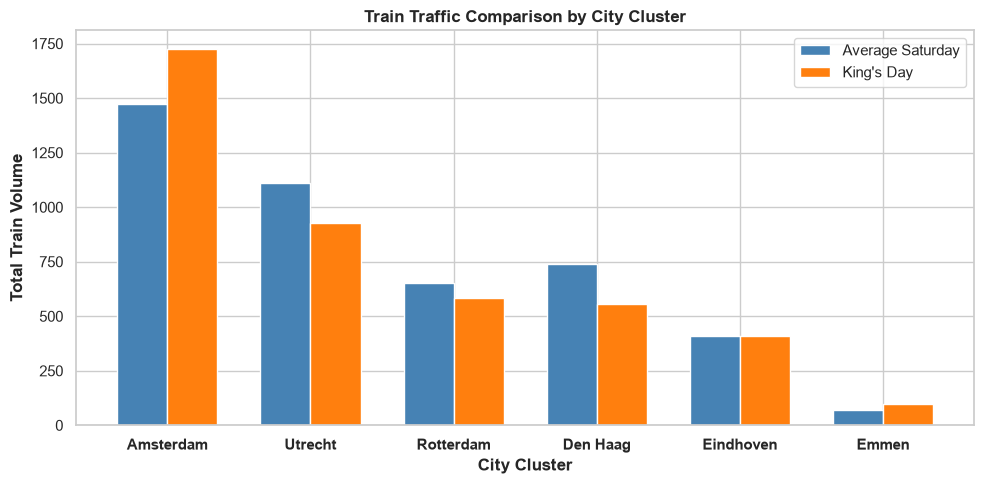

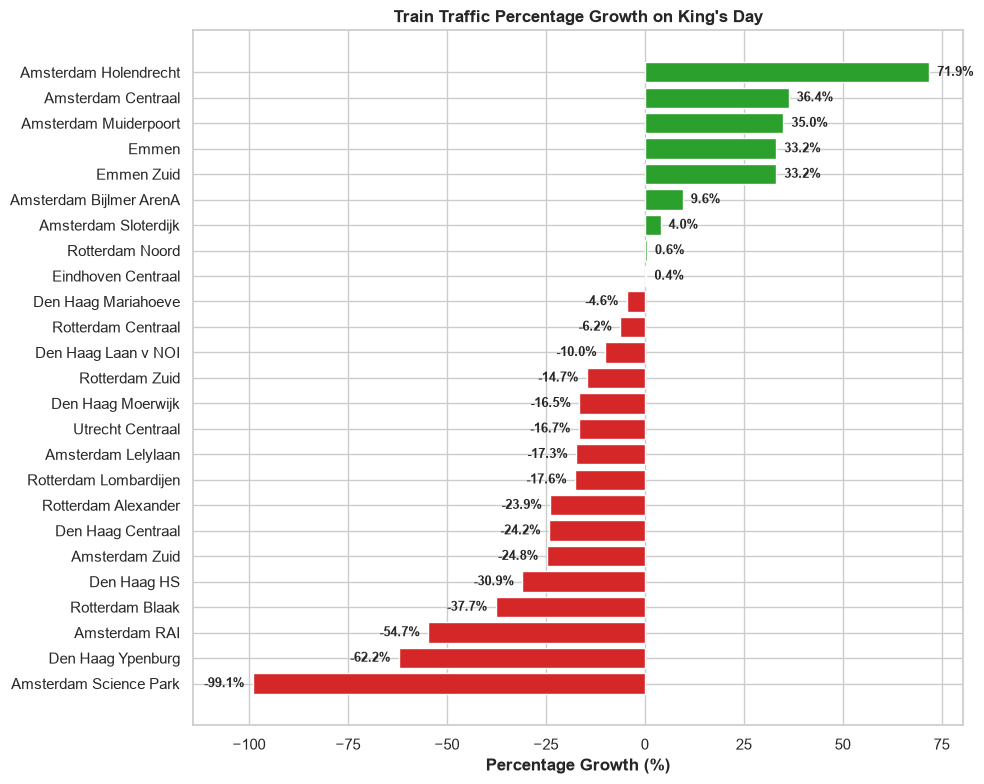

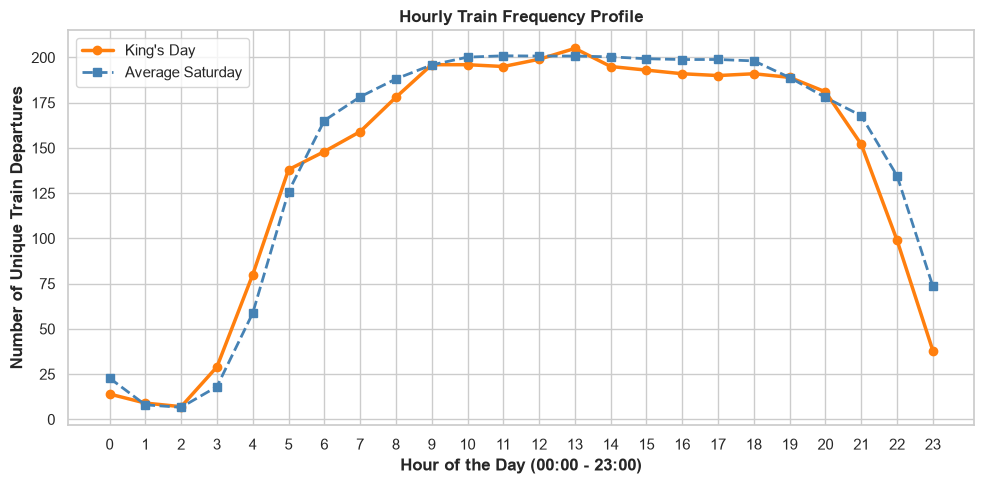

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Dataset loading
columns_to_load = ['Service:Date', 'Service:RDT-ID', 'Stop:Station name', 'Stop:Departure time']
file_path = r"C:\Users\chris\OneDrive - Delft University of Technology\Year 2026-2027\TIL6022 Groep 14\traindata_filtered_2024.csv"

df = pd.read_csv(file_path, usecols=columns_to_load)

# Convert string to datatime for relevant columns
df['Service:Date'] = pd.to_datetime(df['Service:Date'])
df['Stop:Departure time'] = pd.to_datetime(df['Stop:Departure time'], errors='coerce', utc=True)

# Target stations in scope of subquestion 2
target_stations = [
    # Amsterdam
    "Amsterdam Bijlmer ArenA", "Amsterdam Centraal", "Amsterdam Holendrecht", 
    "Amsterdam Lelylaan", "Amsterdam Muiderpoort", "Amsterdam RAI", 
    "Amsterdam Science Park", "Amsterdam Sloterdijk", "Amsterdam Zuid",
    # Rotterdam
    "Rotterdam Alexander", "Rotterdam Blaak", "Rotterdam Centraal", 
    "Rotterdam Lombardijen", "Rotterdam Noord", "Rotterdam Zuid",
    # Den Haag
    "Den Haag Centraal", "Den Haag HS", "Den Haag Laan v NOI", 
    "Den Haag Mariahoeve", "Den Haag Moerwijk", "Den Haag Ypenburg",
    # Additions
    "Utrecht Centraal", "Eindhoven Centraal", "Emmen", "Emmen Zuid"
]

# Filtering dataset to only include the target stations
df_filtered = df[df['Stop:Station name'].isin(target_stations)].copy()

# Helper columns for analysis
df_filtered['DayOfWeek'] = df_filtered['Service:Date'].dt.dayofweek
df_filtered['Date_Str'] = df_filtered['Service:Date'].dt.strftime('%Y-%m-%d')
df_filtered['Hour'] = df_filtered['Stop:Departure time'].dt.hour
kings_day_date = '2024-04-27'

# Mapping station names to city clusters for easy analysis
def get_city(station_name):
    if station_name.startswith('Amsterdam'): return 'Amsterdam'
    elif station_name.startswith('Rotterdam'): return 'Rotterdam'
    elif station_name.startswith('Den Haag'): return 'Den Haag'
    elif 'Utrecht' in station_name: return 'Utrecht'
    elif 'Eindhoven' in station_name: return 'Eindhoven'
    elif 'Emmen' in station_name: return 'Emmen'
    return 'Other'

df_filtered['City'] = df_filtered['Stop:Station name'].apply(get_city)

#Plot 1:
saturdays_df = df_filtered[(df_filtered['DayOfWeek'] == 5) & (df_filtered['Date_Str'] != kings_day_date)]
kings_day_df = df_filtered[df_filtered['Date_Str'] == kings_day_date]

sat_daily_city = saturdays_df.groupby(['City', 'Date_Str'])['Service:RDT-ID'].nunique().reset_index()
avg_sat_city = sat_daily_city.groupby('City')['Service:RDT-ID'].mean().reset_index(name='Average_Saturday')
kd_city = kings_day_df.groupby('City')['Service:RDT-ID'].nunique().reset_index(name='Kings_Day')

plot_df = pd.merge(avg_sat_city, kd_city, on='City').sort_values(by='Kings_Day', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
bar_width = 0.35
x_indexes = range(len(plot_df))

plt.bar([i - bar_width/2 for i in x_indexes], plot_df['Average_Saturday'], width=bar_width, label='Average Saturday', color='#4682B4')
plt.bar([i + bar_width/2 for i in x_indexes], plot_df['Kings_Day'], width=bar_width, label="King's Day", color='#FF7F0E')

plt.xlabel('City Cluster', fontweight='bold')
plt.ylabel('Total Train Volume', fontweight='bold')
plt.title("Train Traffic Comparison by City Cluster", fontweight='bold')
plt.xticks(list(x_indexes), plot_df['City'], fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

#Plot 2:
sats_per_date_station = saturdays_df.groupby(['Stop:Station name', 'Date_Str'])['Service:RDT-ID'].nunique().reset_index()
avg_sats = sats_per_date_station.groupby('Stop:Station name')['Service:RDT-ID'].mean()
kd_sats = kings_day_df.groupby('Stop:Station name')['Service:RDT-ID'].nunique()

growth_df = pd.DataFrame({'Average_Saturdays': avg_sats, 'Kings_Day': kd_sats}).fillna(0)
growth_df = growth_df[growth_df['Average_Saturdays'] > 0]
growth_df['Pct_Growth'] = ((growth_df['Kings_Day'] - growth_df['Average_Saturdays']) / growth_df['Average_Saturdays']) * 100
growth_df = growth_df.sort_values(by='Pct_Growth', ascending=True)

plt.figure(figsize=(10, 8))
colors = ['#2ca02c' if x >= 0 else '#d62728' for x in growth_df['Pct_Growth']]
bars = plt.barh(growth_df.index, growth_df['Pct_Growth'], color=colors)

for bar in bars:
  width = bar.get_width()
  if width >= 0:
    plt.text(
        width + 2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="bold",
    )
  else:
    plt.text(
        width - 2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        ha="right",
        fontsize=9,
        fontweight="bold",
    )

plt.xlim(left=growth_df["Pct_Growth"].min() - 15)
plt.title("Train Traffic Percentage Growth on King's Day", fontweight='bold')
plt.xlabel("Percentage Growth (%)", fontweight='bold')
plt.tight_layout()
plt.show()


#Plot 3:
kd_hourly = kings_day_df.groupby('Hour')['Service:RDT-ID'].nunique()
sat_hourly_avg = saturdays_df.groupby(['Date_Str', 'Hour'])['Service:RDT-ID'].nunique().reset_index().groupby('Hour')['Service:RDT-ID'].mean()

hourly_plot_df = pd.DataFrame({'Kings_Day': kd_hourly, 'Average_Saturday': sat_hourly_avg}).fillna(0).sort_index()

plt.figure(figsize=(10, 5))
plt.plot(hourly_plot_df.index, hourly_plot_df['Kings_Day'], marker='o', linewidth=2.5, color='#FF7F0E', label="King's Day")
plt.plot(hourly_plot_df.index, hourly_plot_df['Average_Saturday'], marker='s', linewidth=2, color='#4682B4', linestyle='--', label="Average Saturday")

plt.title("Hourly Train Frequency Profile", fontweight='bold')
plt.xlabel("Hour of the Day (00:00 - 23:00)", fontweight='bold')
plt.ylabel("Number of Unique Train Departures", fontweight='bold')
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd

# ==========================================
# 1. INLADEN EN PREPROCESSEN VAN DE DATA
# ==========================================
columns_to_load = [
    'Service:Date',
    'Service:RDT-ID',
    'Stop:Station name',
]
file_path = r'C:\Users\chris\OneDrive - Delft University of Technology\Year 2026-2027\TIL6022 Groep 14\traindata_filtered_2024.csv'

df = pd.read_csv(file_path, usecols=columns_to_load)

# Datumconvertering en datum-string kolom
df['Service:Date'] = pd.to_datetime(df['Service:Date'])
df['Date_Str'] = df['Service:Date'].dt.strftime('%Y-%m-%d')
df['DayOfWeek'] = df['Service:Date'].dt.dayofweek

kings_day_date = '2024-04-27'

# ==========================================
# 2. BEREKENING TOTAAL AANTAL UNIEKE TREINEN
# ==========================================

# A. Unieke ritten op Koningsdag over de gehele dataset/geselecteerde stations
kd_df = df[df['Date_Str'] == kings_day_date]
total_kings_day_trains = kd_df['Service:RDT-ID'].nunique()

# B. Unieke ritten per normale zaterdag (excl. Koningsdag)
saturdays_df = df[
    (df['DayOfWeek'] == 5) & (df['Date_Str'] != kings_day_date)
]
sat_daily_totals = saturdays_df.groupby('Date_Str')['Service:RDT-ID'].nunique()

# C. Gemiddelde van normale zaterdagen
avg_saturday_trains = sat_daily_totals.mean()

# D. Procentueel en absoluut verschil
absolute_diff = total_kings_day_trains - avg_saturday_trains
pct_diff = (absolute_diff / avg_saturday_trains) * 100

#resultaten

print('TOTAAL AANTAL UNIEKE TREINRITTEN OVERZICHT')

print(f'Gemiddelde normale zaterdag: {avg_saturday_trains:.2f} treinen')
print(f'Koningsdag (27 april 2024) : {total_kings_day_trains} treinen')

print(f'Absoluut verschil         : {absolute_diff:+.2f} treinen')
print(f'Procentueel verschil       : {pct_diff:+.2f}%')


TOTAAL AANTAL UNIEKE TREINRITTEN OVERZICHT
Gemiddelde normale zaterdag: 5479.86 treinen
Koningsdag (27 april 2024) : 4943 treinen
Absoluut verschil         : -536.86 treinen
Procentueel verschil       : -9.80%
